# **Homework – Concrete Compressive Strength Regression**

## Overview

In this homework, you will apply the regression concepts covered in class to a new dataset: the **UCI Concrete Compressive Strength Dataset**.

The goal is to predict **concrete compressive strength (MPa)** from the ingredients and age of a concrete mixture.

You will practice:

- Data loading and understanding
- Separating features and target
- Train/test split
- Linear Regression
- `SGDRegressor`
- Regression evaluation metrics
- Feature scaling with `StandardScaler`
- Data leakage
- 5-fold cross-validation
- Polynomial Regression
- Model complexity
- Bias–variance tradeoff
- Model selection
- Saving and loading a model with `joblib`
- Making a prediction on unseen data

**Important:** Complete all questions and include short written explanations where requested.

## **Dataset Information**

The dataset contains **1,030 observations**, **8 quantitative input variables**, and **1 quantitative target variable**.

### Features

| Feature | Description |
|---|---|
| Cement | Cement amount (kg/m³) |
| Blast Furnace Slag | Blast furnace slag amount (kg/m³) |
| Fly Ash | Fly ash amount (kg/m³) |
| Water | Water amount (kg/m³) |
| Superplasticizer | Superplasticizer amount (kg/m³) |
| Coarse Aggregate | Coarse aggregate amount (kg/m³) |
| Fine Aggregate | Fine aggregate amount (kg/m³) |
| Age | Age of concrete (days) |

### Target

**Concrete compressive strength (MPa)**

The dataset is from the UCI Machine Learning Repository.

## **Part 1 – Data Loading, Understanding, and Initial EDA**

Load the Concrete Compressive Strength dataset.

First, inspect the dataset by displaying:

- the shape of the dataset
- the column names
- the first five rows
- the data types
- descriptive statistics

### **Missing Values**

Check whether the dataset contains missing values.



### **Short Exploratory Data Analysis (EDA)**

You are already familiar with basic EDA from class. Perform a **short EDA** to better understand this regression dataset.

Create **at least 3 meaningful visualizations**. You may choose appropriate plots such as:

- histograms/distribution plots
- boxplots
- scatter plots between predictors and compressive strength
- a correlation heatmap
- other appropriate visualizations you learned in class

Your plots should help you understand the variables and their potential relationship with the target variable.

**Important:** Do not create plots simply for the sake of creating plots. For each visualization, briefly explain what it tells you about the data.


In [20]:
# Perform the initial data inspection.
# Write your code here.
import pandas as pd
import numpy as np

df = pd.read_csv('/content/concrete_data-2.csv')
df.shape


(1030, 9)

In [23]:
df.columns

Index(['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
       'coarse_aggregate', 'fine_aggregate ', 'age',
       'concrete_compressive_strength'],
      dtype='object')

In [3]:
# Check for missing values and perform a short EDA.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [21]:
df.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [22]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [4]:
# Create at least 3 meaningful visualizations and briefly interpret your findings.
# Write your code here.
# 1) Correlation Heatmap
df.corr(numeric_only=True).style.background_gradient(cmap='coolwarm')

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
cement,1.000000,-0.275216,-0.397467,-0.081587,0.092386,-0.109349,-0.222718,0.081946,0.497832
blast_furnace_slag,-0.275216,1.000000,-0.323580,0.107252,0.043270,-0.283999,-0.281603,-0.044246,0.134829
fly_ash,-0.397467,-0.323580,1.000000,-0.256984,0.377503,-0.009961,0.079108,-0.154371,-0.105755
water,-0.081587,0.107252,-0.256984,1.000000,-0.657533,-0.182294,-0.450661,0.277618,-0.289633
superplasticizer,0.092386,0.043270,0.377503,-0.657533,1.000000,-0.265999,0.222691,-0.192700,0.366079
coarse_aggregate,-0.109349,-0.283999,-0.009961,-0.182294,-0.265999,1.000000,-0.178481,-0.003016,-0.164935
fine_aggregate,-0.222718,-0.281603,0.079108,-0.450661,0.222691,-0.178481,1.000000,-0.156095,-0.167241
age,0.081946,-0.044246,-0.154371,0.277618,-0.192700,-0.003016,-0.156095,1.000000,0.328873
concrete_compressive_strength,0.497832,0.134829,-0.105755,-0.289633,0.366079,-0.164935,-0.167241,0.328873,1.000000


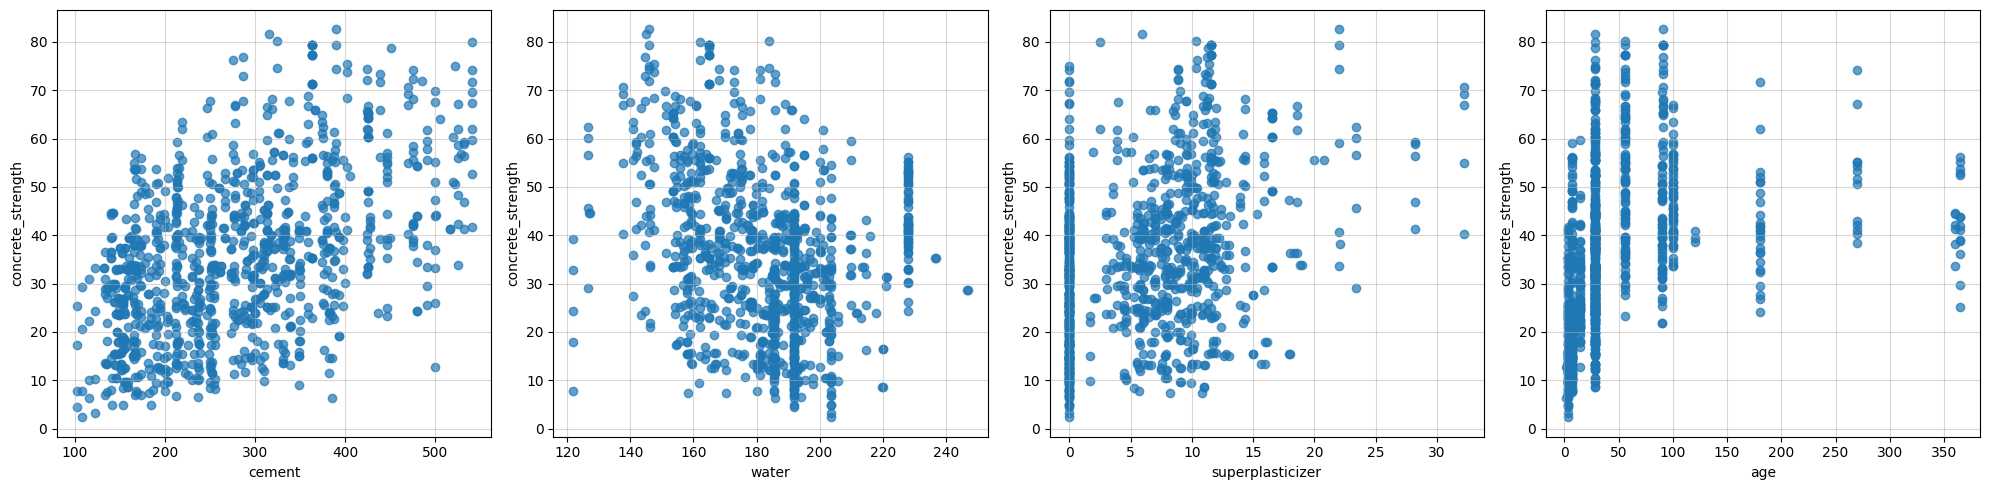

In [32]:
# 2) Scatter plot
import matplotlib.pyplot as plt

def plot_subplot(titles):

  fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20,5))
  for i in range(4):
    x = df[titles[i]]
    axes[i].scatter(x, df['concrete_compressive_strength'], alpha=0.7)
    axes[i].set_ylabel('concrete_strength')
    axes[i].set_xlabel(titles[i])
    axes[i].grid(True, alpha=0.5)

titles = ['cement','water','superplasticizer','age']
plot_subplot(titles)

plt.tight_layout()
plt.show()

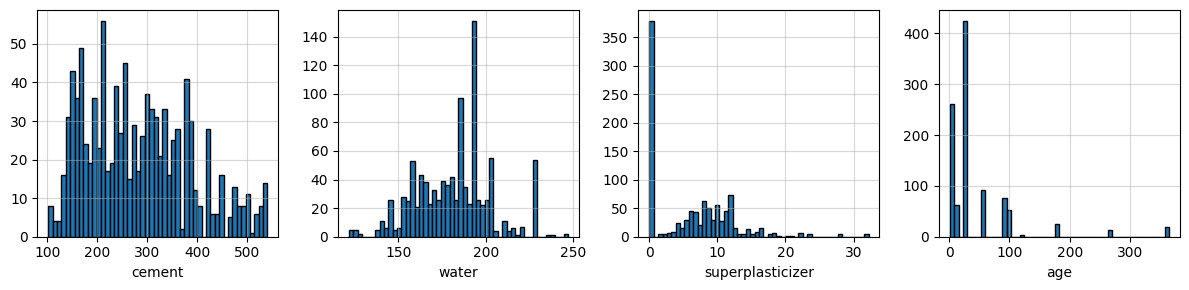

In [25]:
# 3) Histograms
import matplotlib.pyplot as plt

def plot_subplot(titles):

  fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(12,3))
  for i in range(4):
    x = df[titles[i]]
    axes[i].hist(x, bins=50, edgecolor='black')
    axes[i].set_xlabel(titles[i])
    axes[i].grid(True, alpha=0.5)

titles = ['cement','water','superplasticizer','age']
plot_subplot(titles)
plt.tight_layout()
plt.show()

### **Question 1 – Missing Values**

Does the dataset contain any missing values?

If yes, identify the variables and the number of missing values.
If no, clearly state that there are no missing values.

### **Question 2 – Exploratory Data Analysis**

Based on your descriptive statistics and visualizations, describe **at least three specific observations** about the dataset.

Your observations should be supported by your EDA.


**Your Answer:**

Q1: There are no missing values from df.info().

Q2:

1. **cement and concrete compressive strength:**
   Strongest positive correlation at about 0.50.  This is supported in the first scatter plot. A higher cement content increases the strength of concrete.

2. **superplasticizer and concrete compressive strength:**
   Moderate positive correlation at about 0.37.

3. **water and concrete compressive strength:**
   Moderate negative correlation at about -0.29. A higher water content reduces the strength of concrete.

4. superplasticizer was not used in about one third of obervations. There is a outlier at x=0 in the third histogram.

5. There are several gaps within the age range in the fourth histogram.

### **Question 3**

How many observations and predictor variables are in the dataset?

Which column is the target variable?


**Your Answer:**

1030 observations and 8 predictor variables.

concrete_compressive_strength is the target variable.

## **Part 2 – Data Preparation**

Separate the features (`X`) and target (`y`).

Then split the dataset into training and testing sets.

Use:

- `test_size=0.2`
- `random_state=42`

Display the shapes of the training and testing sets.

In [10]:
# Write your code here
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop(columns=['concrete_compressive_strength'])
y = df['concrete_compressive_strength']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (824, 8)
X_test shape: (206, 8)
y_train shape: (824,)
y_test shape: (206,)


In [ ]:
# Write your code here

## **Part 3 – Multiple Linear Regression**

Train a `LinearRegression` model using the training data.

Predict the target values for the test set.

Calculate and report:

- MAE
- MSE
- RMSE
- R²

In [11]:
# Write your code here
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 7.745559243921434
MSE: 95.9709400911068
RMSE: 9.796475901624358
R²: 0.627553179231485


In [ ]:
# Write your code here

### **Question 4**

Based on the four evaluation metrics, how well does the Multiple Linear Regression model perform?

Briefly explain what RMSE and R² tell you about the model.

**Your Answer:**

**1. Performance Evaluation**

The Multiple Linear Regression model shows a moderate baseline performance with the following metrics:
- **MAE** (Mean Absolute Error): $\approx 7.75$ MPa
- **MSE** (Mean Squared Error): $\approx 95.97$ MPa$^2$
- **RMSE** (Root Mean Squared Error): $\approx 9.80$ MPa
- **R² Score:** $\approx 0.628$ ($62.8\%$)

**2. Interpretation of RMSE and R²**

- An RMSE of 9.80 MPa indicates that the predicted concrete compressive strengths typically differ from the actual values by approximately 9.80 MPa.    

- An R² value of $0.628$ indicates that approximately $62.8\%$ of the variation in concrete compressive strength is explained by our 8 features. The remaining $37.2\%$ of the variation is due to non-linear patterns, unexplained variation, or random noise.

## **Part 4 – Gradient Descent Regression**

Train an `SGDRegressor` using the following parameters:

```python
max_iter=1000
tol=1e-3
random_state=42
```

First, train the model using the **unscaled** training data.

Predict the test set and calculate:

- MAE
- MSE
- RMSE
- R²

In [12]:
# Write your code here
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sgd_model = SGDRegressor(max_iter=1000, tol=1e-3, random_state=42)
# Train on the unscaled train data
sgd_model.fit(X_train, y_train)
# Predict on the test data
y_pred = sgd_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 314437289848188.94
MSE: 1.1580386126444226e+29
RMSE: 340299663920554.4
R²: -4.49414999162402e+26


In [ ]:
# Write your code here

### **Question 5**

Compare the SGD results with Multiple Linear Regression.

Do you notice anything unusual about the unscaled `SGDRegressor` results?

Why might this happen?

**Your Answer:**

Based on RMSE and R², SGD test errors are huge compared to Multiple Linear Regression.

SGDRegesssor uses unscaled training data. Features are in different numerical ranges. Large-scale features dominate the regression update steps. It was unable to converge to the optimal solution due to overshoot.

## **Part 5 – Feature Scaling**

Use `StandardScaler` to standardize the features.

**Important:** Fit the scaler using only the training data.

Then transform both the training and testing data.

Display the mean and standard deviation of the scaled training data.

In [13]:
# Write your code here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("mean of X_train:", X_train_scaled.mean(axis=0))
print("\nstd of X_train:", X_train_scaled.std(axis=0))

mean of X_train: [ 2.99652428e-16  3.44923658e-17  8.62309145e-18  1.06926334e-15
 -1.55215646e-16  4.18219935e-16 -6.42420313e-16 -3.01808201e-17]

std of X_train: [1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
# Write your code here

### **Question 6 – Data Leakage**

Should the scaler be fit before or after the train-test split?

Explain why.

**Your Answer:**

The scaler should be fit after the train-test split to avoid data leakage.

The fit step should not see the test data. The fit() call is on the training data but not on the test data so that the scaler computes the statistics using only the training data.

### **Scaled SGDRegressor**

Train the same `SGDRegressor` using the scaled training data.

Predict the test set and calculate:

- MAE
- MSE
- RMSE
- R²

Then compare the scaled and unscaled SGD models.

In [14]:
# Write your code here
import numpy as np

sgd_model.fit(X_train_scaled, y_train);
y_pred = sgd_model.predict(X_test_scaled);

mae = mean_absolute_error(y_test, y_pred);
mse = mean_squared_error(y_test, y_pred);
rmse = np.sqrt(mse);
r2 = r2_score(y_test, y_pred);

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 7.799210553940247
MSE: 96.45909919904327
RMSE: 9.82135933560336
R²: 0.6256587171411113


The scaled SGD model performs much better than the unscaled SGD model based on RMSE and R².

Scaled SGD:

RMSE (9.82135933560336),
R² (0.6256587171411113)

Unscaled SGD:

RMSE (340299663920554.4),
R² (-4.49414999162402e+26)


In [ ]:
# Write your code here

### **Question 7**

Why did feature scaling affect `SGDRegressor` much more than ordinary `LinearRegression`?

Explain in your own words.

**Your Answer:**

Gradient descent algorithms, such as SGDRegressor, are highly sensitive to the scale of input features. Features with larger scales can dominate parameter updates. Differences in feature scales may slow convergence and cause the algorithm to overshoot the optimal solution.

In contrast, the LinearRegression model calculates the optimal weights analytically, without requiring iterative parameter updates. It is less affected by the scale of features.

## **Part 6 – 5-Fold Cross-Validation**

Use **5-fold cross-validation** with `LinearRegression`.

Calculate the **MSE** for each fold and convert the values to **RMSE**.

Report:

- RMSE for each fold
- mean RMSE
- standard deviation of RMSE

In [15]:
# Write your code here
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
import numpy as np

lr_model = LinearRegression()
neg_mse_scores = cross_val_score(lr_model, X_train_scaled, y_train, cv=5, scoring='neg_mean_squared_error')

rmse_scores = np.sqrt(-neg_mse_scores)
mean_rmse = rmse_scores.mean()
std_rmse = rmse_scores.std()

print("RMSE for each fold:")
for i, score in enumerate(rmse_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\nMean RMSE: {mean_rmse:.4f}")
print(f"Standard Deviation of RMSE: {std_rmse:.4f}")

RMSE for each fold:
  Fold 1: 11.7993
  Fold 2: 11.9312
  Fold 3: 9.3705
  Fold 4: 9.8521
  Fold 5: 10.3682

Mean RMSE: 10.6643
Standard Deviation of RMSE: 1.0310


### **Question 8**

What does the standard deviation of the cross-validation RMSE values tell you about model performance?

Is the model performance relatively consistent across the five folds?

**Your Answer:**

1. RMSE across the five folds has a mean at around 10 with a very small standard deviation at about 1.0.

2. The model performance is stable and relatively consistent across the five folds.

## **Part 7 – Polynomial Regression**

The UCI documentation describes concrete compressive strength as a **highly nonlinear function of age and ingredients**.

Use `PolynomialFeatures` and `LinearRegression` to investigate whether increasing model complexity improves prediction.

Test the following polynomial degrees:

- Degree 1
- Degree 2
- Degree 3
- Degree 4

For each degree:

1. Transform the training and testing features.
2. Train a `LinearRegression` model.
3. Calculate training RMSE.
4. Calculate testing RMSE.
5. Calculate training R².
6. Calculate testing R².

Create a table containing all results.

In [16]:
# Write your code here
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

table = []
for d in range(1, 5):
    # transform
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    # train
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    table.append([d, train_rmse, test_rmse, train_r2, test_r2])
    print(f"Degree {d}: train_rmse: {train_rmse}")
    print(f"Degree {d}: test_rmse: {test_rmse}")
    print(f"Degree {d}: train_r2: {train_r2}")
    print(f"Degree {d}: test_r2: {test_r2}\n")

df = pd.DataFrame(table, columns=['Degree', 'train_rmse', 'test_rmse', 'train_r2', 'test_r2'])
df

Degree 1: train_rmse: 10.518787334819802
Degree 1: test_rmse: 9.796475901624364
Degree 1: train_r2: 0.6105238047649741
Degree 1: test_r2: 0.6275531792314848

Degree 2: train_rmse: 7.287123951892045
Degree 2: test_rmse: 7.45536436940061
Degree 2: train_r2: 0.8130773700411071
Degree 2: test_r2: 0.7842939778598572

Degree 3: train_rmse: 4.4254183054876295
Degree 3: test_rmse: 6.34864033417266
Degree 3: train_r2: 0.9310620721581929
Degree 3: test_r2: 0.8435822730932908

Degree 4: train_rmse: 2.1796551074408885
Degree 4: test_rmse: 82.99799299804802
Degree 4: train_r2: 0.9832765787993568
Degree 4: test_r2: -25.733739005687834



,Degree,train_rmse,test_rmse,train_r2,test_r2
0,1,10.518787,9.796476,0.610524,0.627553
1,2,7.287124,7.455364,0.813077,0.784294
2,3,4.425418,6.348640,0.931062,0.843582
3,4,2.179655,82.997993,0.983277,-25.733739


In [ ]:
# Write your code here

### **Question 9**

What happens to training error as polynomial degree increases?

What happens to testing error?

Describe the pattern you observe.

**Your Answer:**

1. Training error decreases from Degree 1 to 4 (10.52 to 7.29 to 4.43 to 2.18).

2. Testing error decreases from Degree 1 to 3 (9.8 to 7.46 to 6.35).
Then it jumps to 83 at Degree 4.

3. Training error decreases monotonically as degree increases. Testing Error decreases initially, reaches a minimum (Degree = 3), and then increases as overfitting takes over (Degree = 4). This is also reflected by the R² of -25.73 at Degree 4.

### **Question 10 – Bias–Variance Tradeoff**

Using your results, identify:

- a degree that appears to underfit
- a degree that gives a good balance between training and testing performance
- a degree that appears to overfit, if one is observed

Explain your reasoning.

**Your Answer:**

1. **Underfit:** Degree 1.
- high training RMSE (10.52).
- training RMSE close to testing RMSE (9.80), and R² score is low.
- high bias. Poor performance on both training and testing data.

2. **Good balance:** Degreee 3.
- Lowest testing RMSE (6.35).
- training RMSE (4.43) lower than testing RMSE.

3. **Overfit:** Degree 4.
- low training RMSE (2.18).
- much higher testing RMSE (82.99) and R² of -25.73.
- high variance. The model overfit the training data and captured noise, resulting in poor generalization on testing data.

### **Question 11 – Model Selection**

Based on the **testing RMSE**, which polynomial degree would you select as your final model?

Explain why you selected it.

Do **not** choose the degree based only on training RMSE or training R².

**Your Answer:**

I would select Degree 3 as the final model.

**Reasoning:**
- Lowest testing RMSE (6.35).  
- highest testing R² (0.84).
- Training RMSE (4.43) is lower than testing RMSE.
- Optimal model complexity.

## **Part 8 – Final Model**

Using the polynomial degree you selected, train a final model using the original train/test split.

Report:

- selected polynomial degree
- test RMSE
- test R²

In [17]:
# Write your code here
poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

lr_model = LinearRegression()
lr_model.fit(X_train_poly, y_train)

y_train_pred = lr_model.predict(X_train_poly)
y_test_pred = lr_model.predict(X_test_poly)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Selected Polynomial Degree: 3")
print(f"Test RMSE: {test_rmse}")
print(f"Test R²: {test_r2}")

Selected Polynomial Degree: 3
Test RMSE: 6.34864033417266
Test R²: 0.8435822730932908


## **Part 9 – Model Deployment**

Retrain your selected polynomial model on the **entire dataset** so that it can be prepared for deployment.

Save:

- the polynomial converter as `concrete_poly_converter.joblib`
- the trained regression model as `final_concrete_model.joblib`

Then reload both objects to demonstrate that they can be used after saving.

In [18]:
# Write your code here
from joblib import dump, load

# Save converter and model
dump(poly, 'concrete_poly_converter.joblib')
dump(lr_model, 'final_concrete_model.joblib')

# Reload
poly = load('concrete_poly_converter.joblib')
lr_model = load('final_concrete_model.joblib')

# Predict using test data
y_test_pred2 = lr_model.predict(poly.transform(X_test_scaled))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred2))
test_r2 = r2_score(y_test, y_test_pred2)

print(f"Selected Polynomial Degree: 3")
print(f"Test RMSE: {test_rmse}")
print(f"Test R²: {test_r2}")

Selected Polynomial Degree: 3
Test RMSE: 6.34864033417266
Test R²: 0.8435822730932908


### **Question 12 – Prediction on Unseen Data**

Use your saved model to predict the compressive strength for this **new concrete mixture**:

| Feature | Value |
|---|---:|
| Cement | 300 |
| Blast Furnace Slag | 100 |
| Fly Ash | 50 |
| Water | 180 |
| Superplasticizer | 10 |
| Coarse Aggregate | 1000 |
| Fine Aggregate | 750 |
| Age | 28 |

Create a DataFrame with these values, transform it using your saved polynomial converter, and use your saved model to make the prediction.

Report the predicted compressive strength in **MPa**.

In [19]:
# Write your code here
df = pd.DataFrame({
    'cement': [300.0],
    'blast_furnace_slag': [100.0],
    'fly_ash': [50.0],
    'water': [180.0],
    'superplasticizer': [10.0],
    'coarse_aggregate': [1000.0],
    'fine_aggregate ': [750.0],
    'age': [28]
})

# 1. Scale the raw input features using the already-fitted scaler
new_data_scaled = scaler.transform(df)

# 2. Transform into polynomial features
new_data_poly = poly.transform(new_data_scaled)

# 3. Predict the compressive strength
pred = lr_model.predict(new_data_poly)
print("Predicted Compressive Strength (MPa):", pred[0])

Predicted Compressive Strength (MPa): 43.47743988322689


## **Final Reflection**

### **Question 13**

Answer the following briefly:

1. Why is scaling important for `SGDRegressor`?
2. Why must the scaler be fitted only on training data?
3. Why can a high-degree polynomial model overfit?
4. Why should model selection be based on test/validation performance rather than training performance?
5. What is the main advantage of cross-validation?

**Your Answers:**

1. Gradient descent algorithms, such as SGDRegressor, are highly sensitive to the scale of input features. Features with larger scales can dominate parameter updates. Differences in feature scales may slow convergence and cause the algorithm to overshoot the optimal solution.

2. Fitting the scaler on the test data causes data leakage. As a result, training will see the test data, leading to over-optimistic test performace.

3. A high-degree polynomial model tends to capture noise in the training process, resulting in low training error but poor generalization on unseen data.

4. The training process learns patterns and statistical relationships from the training data. Test/Validation performance provides a more reliable indication of how well the model generalizes to unseen data and should be used for model selection.

5. In n-fold cross-validation, the training set is divided into n approximately equal-sized, mutually exclusive subsets (called folds). Each fold is used for validation exactly once, while the remaining folds are used for training. This process provides a more robust estimate of the model’s generalization performance.